
# Air Quality Analysis: Beijing (2013–2017)

## Project Overview

This project analyzes historical air quality data collected from 12 monitoring stations across Beijing, China, from March 2013 to February 2017.

The analysis focuses on identifying air pollution trends, comparing pollution levels across monitoring stations, and exploring the relationship between wind speed and PM2.5 concentrations.

The findings will be used to provide insights and data-driven recommendations related to air quality monitoring.

## Dataset Information

- **Dataset:** Beijing Multi-Site Air Quality Dataset
- **Location:** Beijing, China
- **Number of Monitoring Stations:** 12
- **Observation Period:** March 2013 – February 2017
- **Data Frequency:** Hourly
- **Total Observations:** 420,768

## Project Objectives

1. Analyze monthly trends in PM2.5 and PM10 concentrations.
2. Identify monitoring stations with the highest and lowest average PM2.5 concentrations.
3. Explore the relationship between wind speed and PM2.5 concentrations.
4. Provide data-driven recommendations based on the analysis results.


## 1. Business Understanding

### Business Questions

**Question 1: Air Pollution Trends**

How do monthly average PM2.5 and PM10 concentrations change from March 2013 to February 2017?

**Question 2: Station Comparison**

Which monitoring stations record the highest and lowest average PM2.5 concentrations from March 2013 to February 2017?

**Question 3: Wind Speed and PM2.5 Relationship**

How does average PM2.5 concentration differ across wind speed categories at all monitoring stations from March 2013 to February 2017?


In [43]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [44]:

# Check current working directory
print("Current working directory:")
print(Path.cwd())

# Check project data directory
print("\nAvailable files and folders:")
print(list(Path.cwd().iterdir()))


Current working directory:
c:\Users\itsri\Documents\submission\notebook

Available files and folders:
[WindowsPath('c:/Users/itsri/Documents/submission/notebook/notebook.ipynb')]



## 2. Data Gathering

### 2.1 Define Dataset Directory

The dataset consists of 12 CSV files representing different air quality monitoring stations in Beijing.

All dataset files are stored in the `data` directory. The files will be accessed using Python's `pathlib` library to ensure flexible and readable file path management.


In [45]:

# Define the dataset directory
DATA_DIR = Path("../data/PRSA_Data_20130301-20170228")

# Check whether the directory exists
print("Dataset directory exists:", DATA_DIR.exists())

# Display dataset directory
print("Dataset directory:", DATA_DIR.resolve())


Dataset directory exists: True
Dataset directory: C:\Users\itsri\Documents\submission\data\PRSA_Data_20130301-20170228


In [46]:

# Retrieve all CSV files
csv_files = sorted(DATA_DIR.glob("PRSA_Data_*.csv"))

# Display the number of CSV files
print("Total CSV files:", len(csv_files))

# Display all available files
for file in csv_files:
    print(file.name)

# Validate the number of files
assert len(csv_files) == 12, (
    f"Expected 12 CSV files, but found {len(csv_files)}"
)


Total CSV files: 12
PRSA_Data_Aotizhongxin_20130301-20170228.csv
PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_Dingling_20130301-20170228.csv
PRSA_Data_Dongsi_20130301-20170228.csv
PRSA_Data_Guanyuan_20130301-20170228.csv
PRSA_Data_Gucheng_20130301-20170228.csv
PRSA_Data_Huairou_20130301-20170228.csv
PRSA_Data_Nongzhanguan_20130301-20170228.csv
PRSA_Data_Shunyi_20130301-20170228.csv
PRSA_Data_Tiantan_20130301-20170228.csv
PRSA_Data_Wanliu_20130301-20170228.csv
PRSA_Data_Wanshouxigong_20130301-20170228.csv



### 2.2 Load and Combine Datasets

Each CSV file represents a different air quality monitoring station.

The datasets will be loaded individually using pandas. A new `station` column will be added to identify the origin of each observation.

Afterward, all DataFrames will be combined into a single DataFrame using `pd.concat()`.

This approach allows the analysis to cover all 12 monitoring stations within a unified dataset.


In [47]:

# Initialize an empty list
dataframes = []

# Load each CSV file
for file in csv_files:

    # Read CSV file
    temp_df = pd.read_csv(file)

    # Extract station name from filename
    station_name = file.stem.replace(
        "PRSA_Data_", ""
    ).replace(
        "_20130301-20170228", ""
    )

    # Add station identifier
    temp_df["station"] = station_name

    # Append DataFrame
    dataframes.append(temp_df)

# Combine all DataFrames
df = pd.concat(dataframes, ignore_index=True)

print("Dataset successfully combined!")


Dataset successfully combined!


In [48]:

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display unique monitoring stations
print("\nNumber of Stations:", df["station"].nunique())

# Display observations per station
print("\nObservations per Station:")
print(df["station"].value_counts().sort_index())

# Display first five records
print("\nFirst Five Records:")
display(df.head())


Dataset Shape: (420768, 18)

Number of Stations: 12

Observations per Station:
station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
Name: count, dtype: int64

First Five Records:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin



## 3. Data Assessing

### 3.1 Checking Dataset Structure

This section examines the dataset structure, including the number of observations, column names, data types, and memory usage.

The purpose is to ensure that each variable is stored using an appropriate data type before further analysis.


In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  str    
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 62.2 MB


In [50]:
df.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000



### 3.2 Checking Missing Values

Missing values occur when certain observations are not recorded or are unavailable.

This section identifies the number and percentage of missing values in each column to determine which variables require data cleaning.


In [51]:

# Calculate missing values
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": (
        df.isnull().sum() / len(df) * 100
    )
})

# Filter columns with missing values
missing_values = missing_values[
    missing_values["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_values)


,Missing Values,Percentage (%)
CO,20701,4.919813
O3,13277,3.155421
NO2,12116,2.879497
SO2,9021,2.143937
PM2.5,8739,2.076916
PM10,6449,1.532674
wd,1822,0.433018
DEWP,403,0.095777
TEMP,398,0.094589
PRES,393,0.093401


In [52]:

# Calculate total missing values
total_missing = df.isnull().sum().sum()

# Calculate total missing percentage
total_missing_percentage = (
    total_missing / (df.shape[0] * df.shape[1])
) * 100

print("Total Missing Values:", total_missing)
print(
    "Overall Missing Percentage:",
    round(total_missing_percentage, 2), "%"
)


Total Missing Values: 74027
Overall Missing Percentage: 0.98 %



### 3.3 Checking Duplicate Data

Duplicate records may cause inaccurate statistical calculations.

This section checks for fully duplicated rows and duplicated hourly observations within each monitoring station.


In [53]:

# Check fully duplicated rows
duplicate_rows = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_rows)


Total Duplicate Rows: 0


In [54]:

# Check duplicated observations based on station and time
duplicate_timestamps = df.duplicated(
    subset=["year", "month", "day", "hour", "station"]
).sum()

print(
    "Duplicate Station Timestamps:",
    duplicate_timestamps
)


Duplicate Station Timestamps: 0



### 3.4 Checking Invalid Values

Invalid values are observations that do not match the expected characteristics of a variable.

This section checks negative pollutant concentrations, negative wind speed values, and invalid date-time records.


In [55]:

# Define pollutant columns
pollutant_columns = [
    "PM2.5", "PM10", "SO2",
    "NO2", "CO", "O3"
]

# Check negative pollutant values
for column in pollutant_columns:

    negative_count = (df[column] < 0).sum()

    print(
        f"{column}: {negative_count} negative values"
    )


PM2.5: 0 negative values
PM10: 0 negative values
SO2: 0 negative values
NO2: 0 negative values
CO: 0 negative values
O3: 0 negative values


In [56]:

# Check negative wind speed
negative_wind_speed = (df["WSPM"] < 0).sum()

print(
    "Negative Wind Speed Values:",
    negative_wind_speed
)


Negative Wind Speed Values: 0


In [57]:

# Validate date-time information
datetime_check = pd.to_datetime(
    df[["year", "month", "day", "hour"]],
    errors="coerce"
)

invalid_datetime = datetime_check.isna().sum()

print("Invalid DateTime Records:", invalid_datetime)
print("Earliest Date:", datetime_check.min())
print("Latest Date:", datetime_check.max())


Invalid DateTime Records: 0
Earliest Date: 2013-03-01 00:00:00
Latest Date: 2017-02-28 23:00:00



### 3.5 Checking Potential Outliers

The Interquartile Range (IQR) method is used to identify potential outliers in numerical variables.

Observations below the lower bound or above the upper bound are flagged for further investigation.

Potential outliers will not be removed automatically because extreme air pollution measurements may represent actual environmental conditions.


In [58]:

# Select numerical variables for outlier analysis
numerical_columns = [
    "PM2.5", "PM10", "SO2",
    "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP",
    "RAIN", "WSPM"
]

outlier_results = []

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_results.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count
    })

outlier_df = pd.DataFrame(outlier_results)

display(
    outlier_df.sort_values(
        by="Outlier Count",
        ascending=False
    )
)


,Column,Lower Bound,Upper Bound,Outlier Count
2,SO2,-22.50,45.50,35566
4,CO,-1000.00,3000.00,28054
10,WSPM,-1.05,4.15,23079
0,PM2.5,-116.50,247.50,19142
5,O3,-95.50,188.50,16599
9,RAIN,0.00,0.00,16520
1,PM10,-127.50,308.50,14658
3,NO2,-49.00,143.00,7021
6,TEMP,-27.20,53.60,0
8,DEWP,-44.90,51.10,0



### 3.6 Data Assessment Summary

Based on the data quality assessment, several potential issues were identified, including missing values and potential outliers.

Duplicate records and invalid values were also examined to determine whether additional cleaning procedures are required.

The identified issues will be addressed in the next stage through appropriate data cleaning procedures.


In [59]:

# Create data assessment summary
assessment_summary = pd.DataFrame({
    "Issue": [
        "Missing Values",
        "Duplicate Rows",
        "Duplicate Station Timestamps",
        "Negative Pollutant Values",
        "Negative Wind Speed",
        "Invalid DateTime",
        "Potential Outliers"
    ],
    "Count": [
        total_missing,
        duplicate_rows,
        duplicate_timestamps,
        sum((df[col] < 0).sum() for col in pollutant_columns),
        negative_wind_speed,
        invalid_datetime,
        outlier_df["Outlier Count"].sum()
    ]
})

display(assessment_summary)


,Issue,Count
0,Missing Values,74027
1,Duplicate Rows,0
2,Duplicate Station Timestamps,0
3,Negative Pollutant Values,0
4,Negative Wind Speed,0
5,Invalid DateTime,0
6,Potential Outliers,160639



## 4. Missing Value Investigation

### 4.1 Missing Values by Monitoring Station

This section examines the distribution of missing values across all monitoring stations to identify whether certain stations have a higher proportion of incomplete observations.


In [60]:

# Calculate missing values by station
missing_by_station = (
    df.groupby("station")
    .apply(lambda group: group.isnull().sum().sum(),
           include_groups=False)
    .to_frame(name="Missing Values")
)

# Calculate percentage
missing_by_station["Percentage (%)"] = (
    missing_by_station["Missing Values"]
    / (df.groupby("station").size() * len(df.columns))
    * 100
)

display(
    missing_by_station.sort_values(
        by="Missing Values",
        ascending=False
    )
)


,Missing Values,Percentage (%)
station,,
Shunyi,8523,1.350388
Dongsi,7600,1.204147
Huairou,7485,1.185927
Aotizhongxin,7271,1.152020
Dingling,7015,1.111460
Wanliu,6447,1.021466
Guanyuan,5279,0.836407
Tiantan,5277,0.836090
Changping,5166,0.818503



### 4.2 Consecutive Missing Value Analysis

This section investigates consecutive missing observations for each numerical variable within individual monitoring stations.

The analysis helps determine whether temporal interpolation is appropriate and identifies missing sequences that exceed the maximum interpolation limit.


In [61]:

# Define numerical columns
numerical_columns = [
    "PM2.5", "PM10", "SO2",
    "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP",
    "RAIN", "WSPM"
]

# Create datetime column
df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

# Function to calculate consecutive missing sequences
def get_missing_sequences(series):

    missing = series.isna()

    groups = (~missing).cumsum()

    missing_runs = (
        missing[missing]
        .groupby(groups[missing])
        .size()
    )

    return missing_runs

# Analyze missing sequences
gap_results = []

for station in df["station"].unique():

    station_df = (
        df[df["station"] == station]
        .sort_values("datetime")
        .set_index("datetime")
    )

    for column in numerical_columns:

        missing_runs = get_missing_sequences(
            station_df[column]
        )

        gap_results.append({
            "Station": station,
            "Column": column,
            "Missing Count": station_df[column].isna().sum(),
            "Maximum Consecutive Gap": (
                missing_runs.max()
                if not missing_runs.empty else 0
            ),
            "Gap Above 3 Hours": (
                (missing_runs > 3).sum()
            )
        })

gap_analysis = pd.DataFrame(gap_results)

display(
    gap_analysis.sort_values(
        by="Maximum Consecutive Gap",
        ascending=False
    ).head(20)
)


,Station,Column,Missing Count,Maximum Consecutive Gap,Gap Above 3 Hours
37,Dongsi,CO,3197,1517,39
26,Dingling,CO,2012,1051,52
36,Dongsi,NO2,1601,900,25
92,Shunyi,CO,2178,749,48
114,Wanliu,CO,1812,642,30
113,Wanliu,NO2,1070,548,18
93,Shunyi,O3,1489,497,34
101,Tiantan,SO2,1118,457,32
48,Guanyuan,CO,1753,441,43
115,Wanliu,O3,2107,429,81



## 5. Data Cleaning

### 5.1 Creating a Clean Dataset Copy

Before performing data cleaning, a copy of the original dataset is created to preserve the raw data.

All cleaning operations will be performed on the copied DataFrame, while the original dataset remains unchanged.


In [62]:

# Create a copy of the original dataset
df_clean = df.copy()

# Verify dataset copy
print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)

# Check whether both datasets have the same shape
assert df.shape == df_clean.shape

print("\nDataset copy created successfully!")


Original dataset shape: (420768, 19)
Clean dataset shape: (420768, 19)

Dataset copy created successfully!



### 5.2 Handling Missing Values Using Temporal Interpolation

Temporal interpolation is applied to numerical variables to estimate missing observations based on neighboring time-based measurements.

The interpolation is performed separately for each monitoring station to prevent mixing observations from different locations.

Only consecutive missing sequences of up to three hours are interpolated. Longer missing sequences are preserved to avoid generating unreliable estimates.

Categorical wind direction (`wd`) and rainfall (`RAIN`) are excluded from interpolation because their characteristics require different handling approaches.


In [63]:

# Define numerical columns for interpolation
interpolation_columns = [
    "PM2.5", "PM10", "SO2",
    "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "WSPM"
]

# Set maximum consecutive missing values
MAX_GAP = 3

# Store the number of filled values
filled_counts = {
    column: 0
    for column in interpolation_columns
}

# Process each monitoring station separately
for station in df_clean["station"].unique():

    # Select and sort station observations
    station_data = (
        df_clean[df_clean["station"] == station]
        .sort_values("datetime")
    )

    for column in interpolation_columns:

        # Set datetime as index
        series = station_data.set_index("datetime")[column]

        # Identify missing observations
        missing = series.isna()

        # Identify consecutive missing groups
        groups = (~missing).cumsum()

        # Calculate the length of each missing sequence
        gap_lengths = (
            missing.groupby(groups)
            .transform("sum")
        )

        # Select missing sequences with maximum length of 3
        eligible = (
            missing &
            (gap_lengths <= MAX_GAP)
        )

        # Perform time-based interpolation
        interpolated = series.interpolate(
            method="time",
            limit_area="inside"
        )

        # Fill only eligible missing observations
        valid_fill = eligible & interpolated.notna()

        cleaned_series = series.copy()

        cleaned_series.loc[valid_fill] = (
            interpolated.loc[valid_fill]
        )

        # Update the clean DataFrame
        df_clean.loc[station_data.index, column] = (
            cleaned_series.to_numpy()
        )

        # Record the number of filled values
        filled_counts[column] += valid_fill.sum()

# Display interpolation results
interpolation_summary = pd.DataFrame({
    "Column": list(filled_counts.keys()),
    "Filled Values": list(filled_counts.values())
})

display(interpolation_summary)

print(
    "\nTotal interpolated values:",
    sum(filled_counts.values())
)


,Column,Filled Values
0,PM2.5,3454
1,PM10,2687
2,SO2,3265
3,NO2,4268
4,CO,5364
5,O3,5069
6,TEMP,237
7,PRES,242
8,DEWP,242
9,WSPM,198



Total interpolated values: 25026



### 5.3 Evaluating Missing Values After Cleaning

This section compares missing values before and after the cleaning process.

The evaluation ensures that short missing sequences have been handled while longer missing sequences remain unchanged.


In [64]:

# Calculate missing values before and after cleaning
missing_before = df.isnull().sum()

missing_after = df_clean.isnull().sum()

# Create comparison table
missing_comparison = pd.DataFrame({
    "Before Cleaning": missing_before,
    "After Cleaning": missing_after,
    "Filled Values": (
        missing_before - missing_after
    )
})

display(
    missing_comparison[
        missing_comparison["Before Cleaning"] > 0
    ]
)


,Before Cleaning,After Cleaning,Filled Values
PM2.5,8739,5285,3454
PM10,6449,3762,2687
SO2,9021,5756,3265
NO2,12116,7848,4268
CO,20701,15337,5364
O3,13277,8208,5069
TEMP,398,161,237
PRES,393,151,242
DEWP,403,161,242
RAIN,390,390,0


In [65]:
print(
    "Missing values before cleaning:",
    df.isnull().sum().sum()
)

print(
    "Missing values after cleaning:",
    df_clean.isnull().sum().sum()
)

print(
    "Total values filled:",
    df.isnull().sum().sum()
    - df_clean.isnull().sum().sum()
)

Missing values before cleaning: 74027
Missing values after cleaning: 49001
Total values filled: 25026


In [66]:
# Check dataset dimensions
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

# Check duplicate records
print(
    "Duplicate rows after cleaning:",
    df_clean.duplicated().sum()
)

# Check missing values in datetime
print(
    "Missing datetime:",
    df_clean["datetime"].isna().sum()
)

# Check station distribution
print("\nStation distribution:")
print(df_clean["station"].value_counts().sort_index())

Original shape: (420768, 19)
Cleaned shape: (420768, 19)
Duplicate rows after cleaning: 0
Missing datetime: 0

Station distribution:
station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
Name: count, dtype: int64



### 5.4 Data Cleaning Summary

The data cleaning process successfully interpolated 25,026 missing values using time-based interpolation, with a maximum consecutive gap of three hours.

The interpolation was performed separately for each monitoring station to preserve the temporal characteristics of individual locations.

A total of 49,001 missing values remain in the dataset. These values were intentionally retained because they belong to longer missing sequences or variables that were excluded from numerical interpolation, such as rainfall (RAIN) and wind direction (wd).

No duplicate records were found, and the dataset retained all 420,768 observations across the 12 monitoring stations.

The cleaned dataset is considered ready for exploratory data analysis, with remaining missing values handled carefully during subsequent calculations.



## 6. Exploratory Data Analysis (EDA)

### 6.1 Monthly Air Pollution Trends

This analysis examines monthly average PM2.5 and PM10 concentrations across all 12 monitoring stations from March 2013 to February 2017.

The purpose is to identify temporal patterns, seasonal variations, and periods with relatively high or low air pollution concentrations.

#### Monthly Aggregation

The hourly observations are grouped by month, and the average concentrations of PM2.5 and PM10 are calculated for each month.


In [67]:

# Calculate monthly average pollutant concentrations
monthly_summary = (
    df_clean
    .groupby(pd.Grouper(key="datetime", freq="MS"))
    .agg(
        PM25_mean=("PM2.5", "mean"),
        PM25_count=("PM2.5", "count"),
        PM10_mean=("PM10", "mean"),
        PM10_count=("PM10", "count")
    )
    .reset_index()
)

# Display monthly summary
display(monthly_summary.head(12))

# Check number of monthly observations
print(
    "\nTotal months:",
    len(monthly_summary)
)


,datetime,PM25_mean,PM25_count,PM10_mean,PM10_count
0,2013-03-01,104.904952,8885,129.610307,8907
1,2013-04-01,62.231149,8607,95.866903,8614
2,2013-05-01,81.907618,8638,131.446631,8638
3,2013-06-01,102.088301,8471,115.805118,8636
4,2013-07-01,67.855835,8577,76.249858,8813
5,2013-08-01,60.624972,8882,77.460088,8882
6,2013-09-01,76.135141,8628,96.405063,8632
7,2013-10-01,91.888989,8864,112.894983,8889
8,2013-11-01,73.821007,8640,96.244676,8640
9,2013-12-01,78.380254,8898,96.335581,8898



Total months: 48



#### Identifying Highest and Lowest Pollution Months

This section identifies the months with the highest and lowest average PM2.5 and PM10 concentrations throughout the observation period.


In [68]:

# Find highest and lowest PM2.5 months
highest_pm25 = monthly_summary.loc[
    monthly_summary["PM25_mean"].idxmax()
]

lowest_pm25 = monthly_summary.loc[
    monthly_summary["PM25_mean"].idxmin()
]

# Find highest and lowest PM10 months
highest_pm10 = monthly_summary.loc[
    monthly_summary["PM10_mean"].idxmax()
]

lowest_pm10 = monthly_summary.loc[
    monthly_summary["PM10_mean"].idxmin()
]

print("PM2.5")
print(
    "Highest:",
    highest_pm25["datetime"].strftime("%B %Y"),
    round(highest_pm25["PM25_mean"], 2)
)
print(
    "Lowest:",
    lowest_pm25["datetime"].strftime("%B %Y"),
    round(lowest_pm25["PM25_mean"], 2)
)

print("\nPM10")
print(
    "Highest:",
    highest_pm10["datetime"].strftime("%B %Y"),
    round(highest_pm10["PM10_mean"], 2)
)
print(
    "Lowest:",
    lowest_pm10["datetime"].strftime("%B %Y"),
    round(lowest_pm10["PM10_mean"], 2)
)


PM2.5
Highest: December 2015 149.95
Lowest: February 2016 42.85

PM10
Highest: December 2015 159.76
Lowest: February 2016 57.13



#### Monthly PM2.5 and PM10 Trend Visualization

A line chart is used to visualize monthly average PM2.5 and PM10 concentrations over the observation period.

This visualization helps identify long-term trends, fluctuations, and periods with relatively high pollution concentrations.


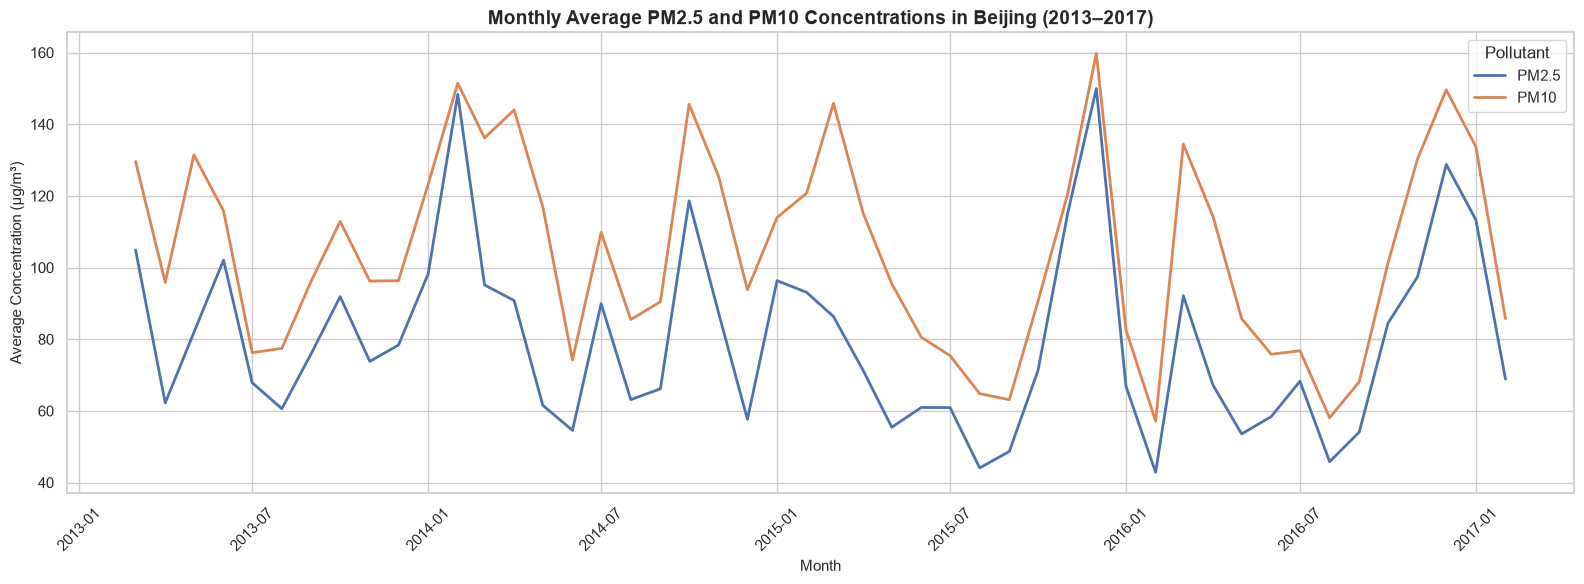

In [69]:

# Create figure
plt.figure(figsize=(16, 6))

# Plot PM2.5 trend
sns.lineplot(
    data=monthly_summary,
    x="datetime",
    y="PM25_mean",
    label="PM2.5",
    linewidth=2
)

# Plot PM10 trend
sns.lineplot(
    data=monthly_summary,
    x="datetime",
    y="PM10_mean",
    label="PM10",
    linewidth=2
)

# Customize chart
plt.title(
    "Monthly Average PM2.5 and PM10 Concentrations in Beijing (2013–2017)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month", fontsize=11)
plt.ylabel("Average Concentration (µg/m³)", fontsize=11)

plt.legend(title="Pollutant")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



#### Explanatory Analysis

The monthly trend analysis shows that PM2.5 and PM10 concentrations fluctuated considerably throughout the observation period from March 2013 to February 2017.

Both pollutants reached their highest monthly average concentrations in December 2015, with PM2.5 reaching 149.95 µg/m³ and PM10 reaching 159.76 µg/m³.

Meanwhile, the lowest monthly average concentrations occurred in February 2016, with PM2.5 at 42.85 µg/m³ and PM10 at 57.13 µg/m³.

These findings indicate that air pollution levels varied substantially over time. The simultaneous peaks and lowest values also suggest similar temporal patterns between the two particulate matter indicators.

However, this analysis describes temporal patterns and does not establish the underlying causes of the observed fluctuations.



### 6.2 Air Pollution Comparison Across Monitoring Stations

This analysis compares average PM2.5 concentrations across the 12 monitoring stations in Beijing during the observation period.

The objective is to identify stations with the highest and lowest average PM2.5 concentrations.

#### Station-Level Aggregation

The dataset is grouped by monitoring station to calculate the average PM2.5 concentration and the number of valid observations for each station.


In [70]:

# Calculate average PM2.5 by station
station_summary = (
    df_clean
    .groupby("station")
    .agg(
        PM25_mean=("PM2.5", "mean"),
        PM25_count=("PM2.5", "count")
    )
    .reset_index()
)

# Sort stations by average PM2.5
station_summary = station_summary.sort_values(
    by="PM25_mean",
    ascending=False
)

display(station_summary)


,station,PM25_mean,PM25_count
3,Dongsi,86.071857,34586
7,Nongzhanguan,84.914347,34767
11,Wanshouxigong,84.822574,34651
5,Gucheng,83.793850,34672
10,Wanliu,83.306231,34898
4,Guanyuan,82.906196,34698
0,Aotizhongxin,82.699035,34408
9,Tiantan,81.975350,34827
8,Shunyi,79.514756,34475
1,Changping,71.084685,34551



#### Identifying Highest and Lowest PM2.5 Stations

This section identifies the monitoring stations with the highest and lowest average PM2.5 concentrations throughout the observation period.


In [71]:

# Identify highest and lowest PM2.5 stations
highest_station = station_summary.loc[
    station_summary["PM25_mean"].idxmax()
]

lowest_station = station_summary.loc[
    station_summary["PM25_mean"].idxmin()
]

print("Highest PM2.5 Station:")
print("Station:", highest_station["station"])
print(
    "Average PM2.5:",
    round(highest_station["PM25_mean"], 2),
    "µg/m³"
)

print("\nLowest PM2.5 Station:")
print("Station:", lowest_station["station"])
print(
    "Average PM2.5:",
    round(lowest_station["PM25_mean"], 2),
    "µg/m³"
)


Highest PM2.5 Station:
Station: Dongsi
Average PM2.5: 86.07 µg/m³

Lowest PM2.5 Station:
Station: Dingling
Average PM2.5: 66.0 µg/m³



#### Average PM2.5 Concentration by Monitoring Station

A horizontal bar chart is used to compare average PM2.5 concentrations across the 12 monitoring stations.

The chart provides a clear ranking of monitoring stations based on their average PM2.5 concentrations.


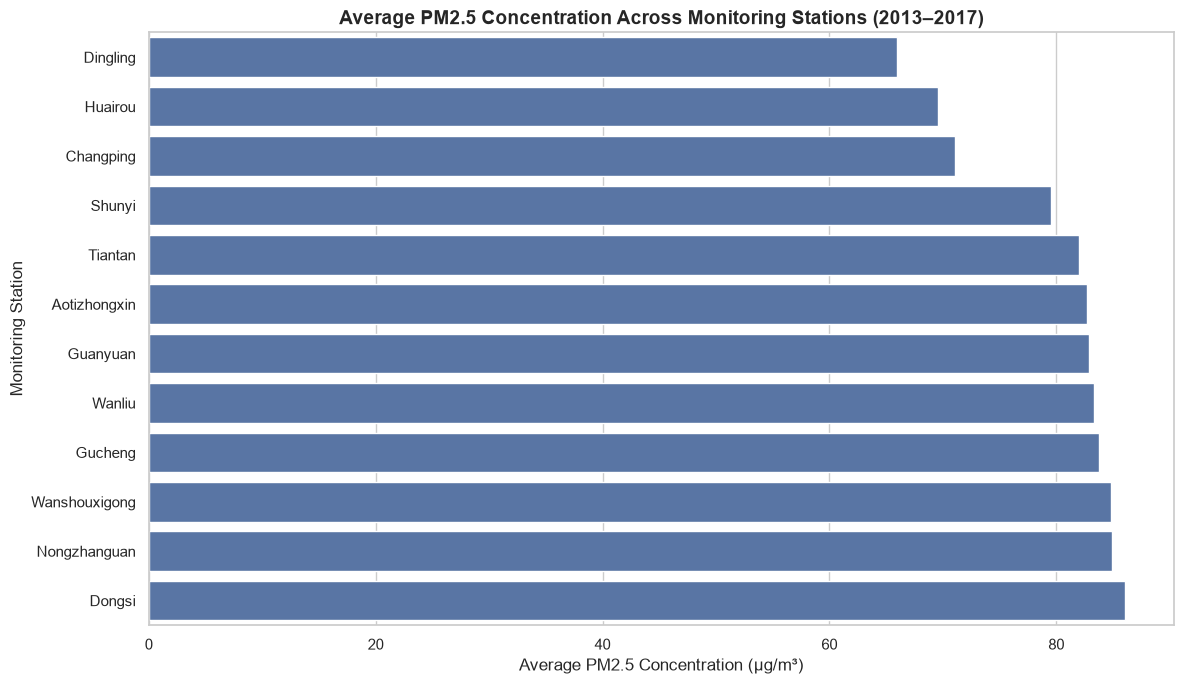

In [72]:

# Sort stations in ascending order for visualization
station_plot = station_summary.sort_values(
    by="PM25_mean",
    ascending=True
)

# Create figure
plt.figure(figsize=(12, 7))

# Create horizontal bar chart
sns.barplot(
    data=station_plot,
    x="PM25_mean",
    y="station"
)

# Customize chart
plt.title(
    "Average PM2.5 Concentration Across Monitoring Stations (2013–2017)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average PM2.5 Concentration (µg/m³)")
plt.ylabel("Monitoring Station")

plt.tight_layout()
plt.show()



#### Explanatory Analysis

The comparison of average PM2.5 concentrations across 12 monitoring stations reveals differences in air pollution levels across monitoring locations.

Dongsi recorded the highest average PM2.5 concentration at 86.07 µg/m³, based on 34,586 valid observations.

In contrast, Dingling recorded the lowest average concentration at 66.00 µg/m³, based on 34,536 valid observations.

The difference between these two stations was 20.07 µg/m³, indicating that the average PM2.5 concentration in Dongsi was approximately 30.4% higher than in Dingling.

These findings highlight spatial variations in PM2.5 concentrations across the monitoring network. Therefore, stations with relatively higher average concentrations may deserve greater attention in air quality monitoring and further investigation.

However, this comparison does not establish the specific causes of the differences between stations.



### 6.3 Relationship Between Wind Speed and PM2.5 Concentration

This analysis investigates how wind speed relates to PM2.5 concentrations across all 12 monitoring stations.

Wind speed is divided into four categories using quartile-based binning. This approach groups observations based on the distribution of wind speed values in the dataset.

The analysis compares average PM2.5 concentrations across the resulting wind speed categories to identify potential patterns.


In [73]:

# Examine wind speed distribution
display(df_clean["WSPM"].describe())

# Calculate quartiles
wind_quantiles = df_clean["WSPM"].quantile(
    [0, 0.25, 0.50, 0.75, 1.00]
)

display(wind_quantiles)


count    420648.000000
mean          1.730039
std           1.246714
min           0.000000
25%           0.900000
50%           1.400000
75%           2.200000
max          13.200000
Name: WSPM, dtype: float64

0.00     0.0
0.25     0.9
0.50     1.4
0.75     2.2
1.00    13.2
Name: WSPM, dtype: float64

In [74]:

# Create analysis dataset
wind_df = df_clean.dropna(
    subset=["WSPM", "PM2.5"]
).copy()

# Calculate unique quartile boundaries
wind_bins = (
    wind_df["WSPM"]
    .quantile([0, 0.25, 0.50, 0.75, 1.00])
    .unique()
)

# Sort bin boundaries
wind_bins = sorted(wind_bins)

# Create category labels
wind_labels = [
    "Low",
    "Moderate",
    "High",
    "Very High"
][:len(wind_bins) - 1]

# Apply binning
wind_df["Wind_Category"] = pd.cut(
    wind_df["WSPM"],
    bins=wind_bins,
    labels=wind_labels,
    include_lowest=True
)

# Display category distribution
print("Wind Speed Categories:")
print(wind_df["Wind_Category"].value_counts().sort_index())


Wind Speed Categories:
Wind_Category
Low          111750
Moderate     104159
High          98514
Very High    100940
Name: count, dtype: int64



#### PM2.5 Aggregation by Wind Speed Category

The dataset is grouped based on wind speed categories to calculate the average PM2.5 concentration and the number of valid observations in each category.


In [75]:

# Calculate average PM2.5 by wind category
wind_summary = (
    wind_df
    .groupby("Wind_Category", observed=False)
    .agg(
        PM25_mean=("PM2.5", "mean"),
        PM25_median=("PM2.5", "median"),
        Observation_Count=("PM2.5", "count"),
        Wind_Speed_Mean=("WSPM", "mean")
    )
    .reset_index()
)

display(wind_summary)


,Wind_Category,PM25_mean,PM25_median,Observation_Count,Wind_Speed_Mean
0,Low,102.354027,77.0,111750,0.580627
1,Moderate,93.363904,69.0,104159,1.191407
2,High,75.121902,53.0,98514,1.798930
3,Very High,45.081382,23.0,100940,3.493085



#### Identifying PM2.5 Levels Across Wind Speed Categories

This section identifies the wind speed categories with the highest and lowest average PM2.5 concentrations.


In [76]:

# Identify highest and lowest PM2.5 categories
highest_wind_category = wind_summary.loc[
    wind_summary["PM25_mean"].idxmax()
]

lowest_wind_category = wind_summary.loc[
    wind_summary["PM25_mean"].idxmin()
]

print("Highest Average PM2.5:")
print(
    "Category:",
    highest_wind_category["Wind_Category"]
)
print(
    "Average PM2.5:",
    round(highest_wind_category["PM25_mean"], 2),
    "µg/m³"
)

print("\nLowest Average PM2.5:")
print(
    "Category:",
    lowest_wind_category["Wind_Category"]
)
print(
    "Average PM2.5:",
    round(lowest_wind_category["PM25_mean"], 2),
    "µg/m³"
)


Highest Average PM2.5:
Category: Low
Average PM2.5: 102.35 µg/m³

Lowest Average PM2.5:
Category: Very High
Average PM2.5: 45.08 µg/m³



#### Average PM2.5 Concentration by Wind Speed Category

A bar chart is used to compare average PM2.5 concentrations across different wind speed categories.

This visualization helps identify whether higher or lower wind speed categories are associated with different average PM2.5 concentrations.


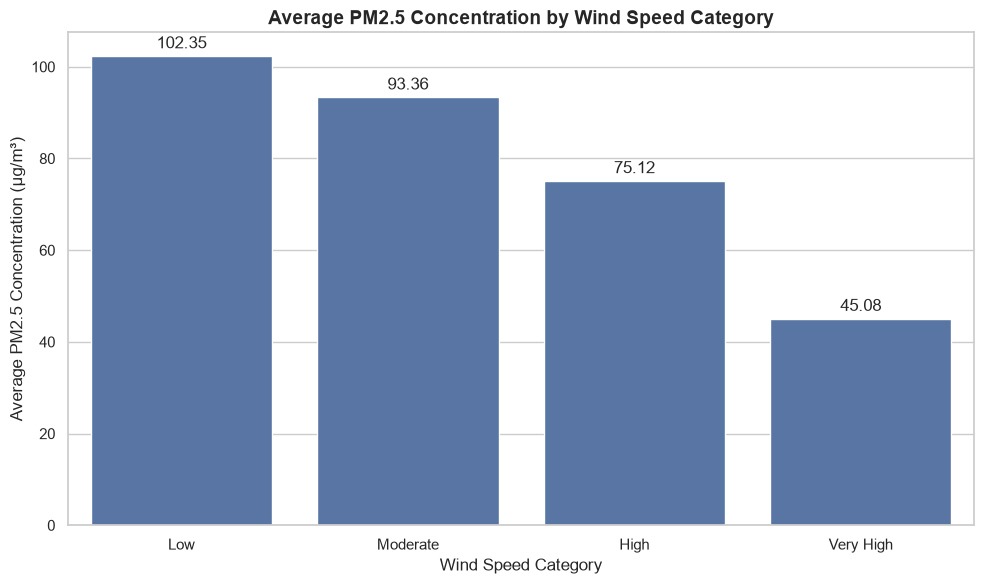

In [77]:

# Create figure
plt.figure(figsize=(10, 6))

# Create bar chart
ax = sns.barplot(
    data=wind_summary,
    x="Wind_Category",
    y="PM25_mean"
)

# Customize chart
plt.title(
    "Average PM2.5 Concentration by Wind Speed Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Wind Speed Category")
plt.ylabel("Average PM2.5 Concentration (µg/m³)")

# Add value labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3
    )

plt.tight_layout()
plt.show()



#### Additional Analysis: Wind Speed and PM2.5 Across Monitoring Stations

This additional analysis examines the average PM2.5 concentration across wind speed categories for each monitoring station.

The purpose is to determine whether the observed relationship between wind speed and PM2.5 is consistent across different monitoring locations.


In [78]:

# Calculate PM2.5 by station and wind category
station_wind_summary = (
    wind_df
    .groupby(
        ["station", "Wind_Category"],
        observed=False
    )
    .agg(
        PM25_mean=("PM2.5", "mean"),
        Observation_Count=("PM2.5", "count")
    )
    .reset_index()
)

# Create pivot table
station_wind_pivot = station_wind_summary.pivot(
    index="station",
    columns="Wind_Category",
    values="PM25_mean"
)

display(station_wind_pivot)


Wind_Category,Low,Moderate,High,Very High
station,,,,
Aotizhongxin,103.783362,100.823045,78.241008,45.655648
Changping,92.743014,82.279935,71.042173,40.911318
Dingling,85.761065,76.640922,66.274861,37.884711
Dongsi,117.788755,103.848649,80.952902,49.391788
Guanyuan,104.400933,100.749208,78.610681,45.808017
Gucheng,100.822163,88.734779,71.029310,44.654445
Huairou,84.891619,75.862307,67.091253,41.270178
Nongzhanguan,116.705390,103.326266,79.310242,47.784939
Shunyi,107.262042,92.149399,73.929776,47.310007



#### Explanatory Analysis

The analysis reveals an inverse pattern between wind speed categories and average PM2.5 concentrations across the 12 monitoring stations.

The Low wind speed category recorded the highest average PM2.5 concentration at 102.35 µg/m³, while the Very High category recorded the lowest average concentration at 45.08 µg/m³.

The average PM2.5 concentration decreased progressively across the four categories: Low (102.35 µg/m³), Moderate (93.36 µg/m³), High (75.12 µg/m³), and Very High (45.08 µg/m³).

The station-level analysis further supports this pattern. Eleven out of twelve monitoring stations showed a consistent decrease in average PM2.5 concentrations as wind speed categories increased. Wanliu was the only station showing a slight increase between the Low and Moderate categories.

These findings suggest an inverse association between wind speed and PM2.5 concentration in the observed dataset. However, the analysis does not establish a causal relationship, as other meteorological and location-related factors may also influence particulate matter concentrations.



## 7. Conclusion & Recommendation

### 7.1 Conclusion

Based on the exploratory data analysis conducted on the Beijing Multi-Site Air Quality Dataset from March 2013 to February 2017, the following conclusions can be drawn:

**1. Monthly Air Pollution Trends**

The monthly analysis shows that PM2.5 and PM10 concentrations fluctuated throughout the observation period. Both pollutants reached their highest monthly average concentrations in December 2015, with PM2.5 at 149.95 µg/m³ and PM10 at 159.76 µg/m³. Their lowest concentrations occurred in February 2016, with PM2.5 at 42.85 µg/m³ and PM10 at 57.13 µg/m³.

**2. Comparison Across Monitoring Stations**

The station-level analysis identified Dongsi as the monitoring station with the highest average PM2.5 concentration at 86.07 µg/m³. Meanwhile, Dingling recorded the lowest average concentration at 66.00 µg/m³. The difference of 20.07 µg/m³ indicates spatial variations in PM2.5 concentrations across the 12 monitoring stations.

**3. Relationship Between Wind Speed and PM2.5**

The analysis revealed an inverse association between wind speed categories and average PM2.5 concentrations. The Low category recorded an average of 102.35 µg/m³, while the Very High category recorded 45.08 µg/m³. This pattern was also observed across 11 of the 12 monitoring stations, suggesting a relatively consistent association across monitoring locations.

### 7.2 Recommendations

Based on the findings, the following actions are recommended:

**1. Prioritize Air Quality Monitoring at High-Concentration Stations**

Dongsi and other stations with relatively high average PM2.5 concentrations should receive greater attention in routine air quality monitoring. Further investigation can be conducted to identify potential local factors contributing to the observed differences.

**2. Strengthen Monitoring During Periods of Low Wind Speed**

Since lower wind speed categories were associated with higher average PM2.5 concentrations, monitoring activities should pay particular attention to periods with relatively low wind speeds. This can help identify potential periods of elevated particulate matter concentrations.

**3. Investigate Historical Pollution Peaks**

The simultaneous peak in PM2.5 and PM10 concentrations in December 2015 deserves further investigation. Historical weather records and other environmental information can be examined to identify possible factors associated with this event.



## 8. Advanced Analysis

### 8.1 Correlation Analysis

Correlation analysis is conducted to examine the statistical relationships between air pollutant concentrations and meteorological variables.

The analysis uses Pearson and Spearman correlation coefficients to identify linear and monotonic relationships between numerical variables.

The results are used to identify variables that have relatively strong positive or negative associations with PM2.5 concentrations.


In [79]:

# Define numerical variables
correlation_columns = [
    "PM2.5", "PM10", "SO2",
    "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP",
    "RAIN", "WSPM"
]

# Calculate Pearson correlation
pearson_corr = df_clean[
    correlation_columns
].corr(method="pearson")

# Calculate Spearman correlation
spearman_corr = df_clean[
    correlation_columns
].corr(method="spearman")

# Display Pearson correlation matrix
print("Pearson Correlation Matrix:")
display(pearson_corr.round(2))

# Display Spearman correlation matrix
print("Spearman Correlation Matrix:")
display(spearman_corr.round(2))


Pearson Correlation Matrix:


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
PM2.5,1.00,0.88,0.48,0.67,0.79,-0.15,-0.13,0.02,0.12,-0.01,-0.27
PM10,0.88,1.00,0.46,0.65,0.70,-0.11,-0.10,-0.02,0.07,-0.03,-0.18
SO2,0.48,0.46,1.00,0.50,0.54,-0.17,-0.32,0.22,-0.27,-0.04,-0.11
NO2,0.67,0.65,0.50,1.00,0.71,-0.47,-0.28,0.17,-0.03,-0.04,-0.40
CO,0.79,0.70,0.54,0.71,1.00,-0.31,-0.32,0.19,-0.06,-0.01,-0.30
O3,-0.15,-0.11,-0.17,-0.47,-0.31,1.00,0.59,-0.44,0.31,0.02,0.30
TEMP,-0.13,-0.10,-0.32,-0.28,-0.32,0.59,1.00,-0.81,0.82,0.04,0.03
PRES,0.02,-0.02,0.22,0.17,0.19,-0.44,-0.81,1.00,-0.75,-0.06,0.07
DEWP,0.12,0.07,-0.27,-0.03,-0.06,0.31,0.82,-0.75,1.00,0.09,-0.30
RAIN,-0.01,-0.03,-0.04,-0.04,-0.01,0.02,0.04,-0.06,0.09,1.00,0.02


Spearman Correlation Matrix:


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
PM2.5,1.00,0.89,0.50,0.66,0.84,-0.25,-0.02,-0.07,0.24,-0.02,-0.33
PM10,0.89,1.00,0.50,0.64,0.73,-0.21,-0.02,-0.08,0.15,-0.08,-0.25
SO2,0.50,0.50,1.00,0.53,0.56,-0.21,-0.36,0.29,-0.34,-0.15,-0.07
NO2,0.66,0.64,0.53,1.00,0.74,-0.61,-0.27,0.18,-0.02,-0.07,-0.44
CO,0.84,0.73,0.56,0.74,1.00,-0.45,-0.22,0.12,0.09,0.01,-0.39
O3,-0.25,-0.21,-0.21,-0.61,-0.45,1.00,0.58,-0.44,0.25,-0.01,0.43
TEMP,-0.02,-0.02,-0.36,-0.27,-0.22,0.58,1.00,-0.82,0.82,0.04,0.10
PRES,-0.07,-0.08,0.29,0.18,0.12,-0.44,-0.82,1.00,-0.76,-0.08,0.04
DEWP,0.24,0.15,-0.34,-0.02,0.09,0.25,0.82,-0.76,1.00,0.18,-0.24
RAIN,-0.02,-0.08,-0.15,-0.07,0.01,-0.01,0.04,-0.08,0.18,1.00,-0.02



### 8.2 Correlation Heatmap

A correlation heatmap is used to visualize the relationships between numerical variables.

The color intensity represents the strength and direction of correlation coefficients, making it easier to identify positive and negative associations.


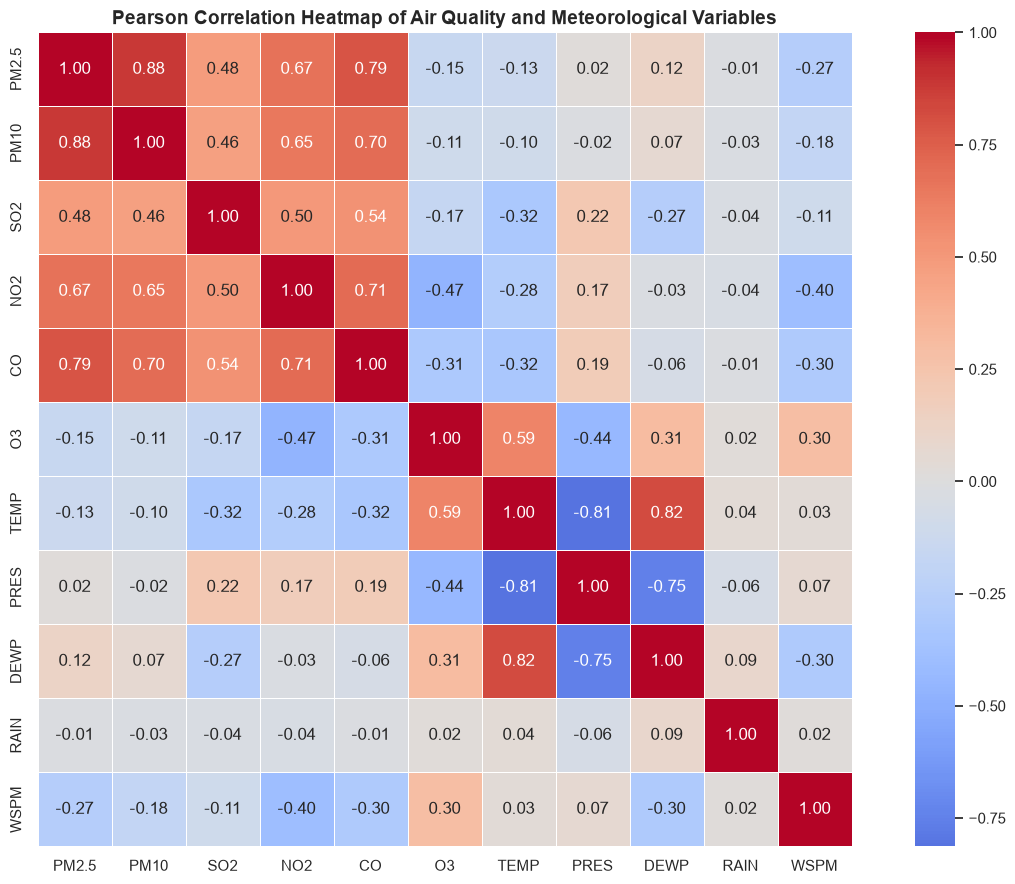

In [80]:

# Create Pearson correlation heatmap
plt.figure(figsize=(13, 9))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title(
    "Pearson Correlation Heatmap of Air Quality and Meteorological Variables",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


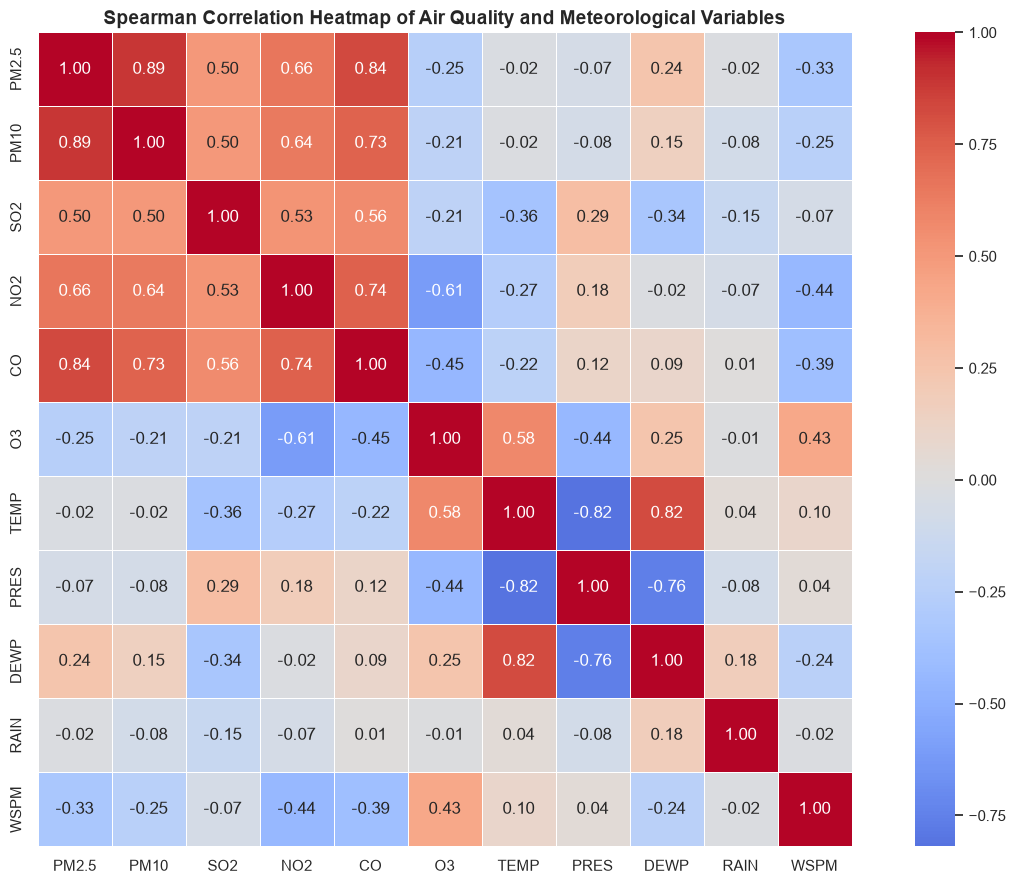

In [81]:

# Create Spearman correlation heatmap
plt.figure(figsize=(13, 9))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title(
    "Spearman Correlation Heatmap of Air Quality and Meteorological Variables",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 8.3 Correlation with PM2.5

This section ranks numerical variables based on their correlation coefficients with PM2.5.

The purpose is to identify variables with relatively strong positive and negative associations with PM2.5 concentrations.


In [82]:

# Extract Pearson correlation with PM2.5
pm25_pearson = (
    pearson_corr["PM2.5"]
    .drop("PM2.5")
    .sort_values(ascending=False)
)

# Extract Spearman correlation with PM2.5
pm25_spearman = (
    spearman_corr["PM2.5"]
    .drop("PM2.5")
    .sort_values(ascending=False)
)

print("Pearson Correlation with PM2.5:")
display(pm25_pearson.to_frame("Correlation"))

print("Spearman Correlation with PM2.5:")
display(pm25_spearman.to_frame("Correlation"))


Pearson Correlation with PM2.5:


,Correlation
PM10,0.881418
CO,0.790024
NO2,0.667137
SO2,0.483077
DEWP,0.115142
PRES,0.018089
RAIN,-0.014399
TEMP,-0.130875
O3,-0.149945
WSPM,-0.272678


Spearman Correlation with PM2.5:


,Correlation
PM10,0.890310
CO,0.836196
NO2,0.658827
SO2,0.500770
DEWP,0.240897
RAIN,-0.020569
TEMP,-0.023477
PRES,-0.070785
O3,-0.254845
WSPM,-0.329450


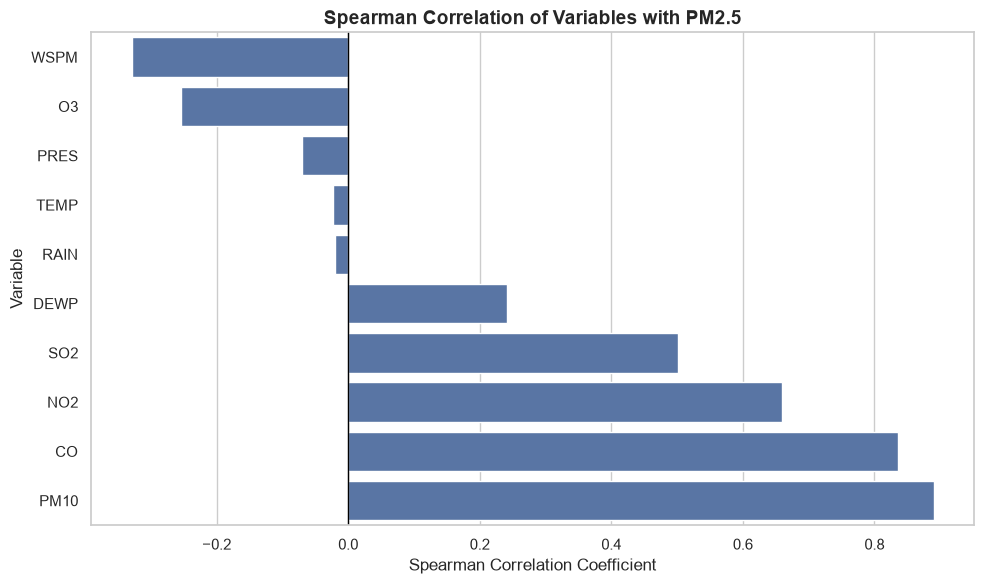

In [83]:

# Prepare correlation data
correlation_plot = (
    pm25_spearman
    .sort_values(ascending=True)
    .reset_index()
)

correlation_plot.columns = [
    "Variable",
    "Correlation"
]

# Create visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    data=correlation_plot,
    x="Correlation",
    y="Variable"
)

plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

plt.title(
    "Spearman Correlation of Variables with PM2.5",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Spearman Correlation Coefficient")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()



### 8.4 Correlation Analysis Findings

The correlation analysis reveals several relationships between PM2.5 concentrations, other air pollutants, and meteorological variables.

Based on Spearman correlation, PM10 has the strongest positive association with PM2.5, with a coefficient of 0.89. CO and NO2 also show relatively strong positive associations, with coefficients of 0.84 and 0.66, respectively.

In contrast, wind speed (WSPM) shows a negative association with PM2.5, with a Spearman coefficient of -0.33. This finding supports the previous analysis, which showed lower average PM2.5 concentrations across higher wind speed categories.

The Pearson and Spearman results generally show similar patterns for the major pollutant variables, although some differences are observed in the strength of their relationships.

The heatmaps also reveal relationships among meteorological variables. For example, TEMP and DEWP have a strong positive Pearson correlation of 0.82, while TEMP and PRES have a negative correlation of -0.81.

Overall, the findings indicate that PM2.5 concentrations are associated with several air pollutants and meteorological variables. However, correlation coefficients do not establish causal relationships, and further analysis would be needed to account for temporal and spatial differences.


In [84]:

# Create dashboard directory
DASHBOARD_DIR = Path("../dashboard")

DASHBOARD_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Export cleaned dataset
dashboard_data = df_clean.copy()

dashboard_data.to_csv(
    DASHBOARD_DIR / "main_data.csv",
    index=False
)

print("Dashboard dataset exported successfully!")
print("Export location:", (DASHBOARD_DIR / "main_data.csv").resolve())
print("Dataset shape:", dashboard_data.shape)


Dashboard dataset exported successfully!
Export location: C:\Users\itsri\Documents\submission\dashboard\main_data.csv
Dataset shape: (420768, 19)
